# Polyp Segmentation — Kvasir-SEG / Medico  (UNet + MiT-B3)
**Architecture:** UNet with MiT-B3 transformer encoder (Segmentation Models PyTorch)  
**Training:** 5-Fold Stratified CV · Differential AdamW · Dice + BCE + Lovász · EMA · AMP  
**Inference:** 5-model ensemble + TTA (H-flip · V-flip · Both)  

## 1 — Install & Imports

In [1]:
# ── Install (run once on a fresh kernel) ────────────────────────────────────
!pip install -q segmentation-models-pytorch albumentations timm
# Lovász is implemented inline — no external install needed


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [2]:
import os, sys, math, random, copy, time, warnings
from pathlib import Path
from collections import defaultdict
from contextlib import contextmanager

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp
from sklearn.model_selection import StratifiedKFold
from tqdm.auto import tqdm  # Progress bars

warnings.filterwarnings('ignore')

# ── Reproducibility ───────────────────────────────────────────────────────────
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


Device: cuda
GPU   : Tesla T4
VRAM  : 15.6 GB


## 2 — Configuration

In [ ]:
class CFG:
    # ── Paths ─────────────────────────────────────────────────────────────────
    # Expected layout: DATA_ROOT/images/  DATA_ROOT/masks/  DATA_ROOT/test/
    DATA_ROOT   = '/kaggle/input/datasets/debeshjha1/medico-automatic-polyp-segmentation-challenge/Medico2020 polyp automatic segmentation dataset/Training dataset/Kvasir-SEG'        # ← set to your dataset path
    TRAIN_IMGS  = '/kaggle/input/datasets/debeshjha1/medico-automatic-polyp-segmentation-challenge/Medico2020 polyp automatic segmentation dataset/Training dataset/Kvasir-SEG/images'
    TRAIN_MASKS = '/kaggle/input/datasets/debeshjha1/medico-automatic-polyp-segmentation-challenge/Medico2020 polyp automatic segmentation dataset/Training dataset/Kvasir-SEG/masks'
    TEST_IMGS   = '/kaggle/input/datasets/debeshjha1/medico-automatic-polyp-segmentation-challenge/Medico2020 polyp automatic segmentation dataset/test dataset/images'
    CKPT_DIR    = Path('./checkpoints')
    PRED_DIR    = Path('./predictions')

    # ── Image ─────────────────────────────────────────────────────────────────
    IMG_SIZE    = 384   # consistent for train AND val (no mismatch)

    # ── Model ─────────────────────────────────────────────────────────────────
    # UNet + MiT-B3: proven on polyp tasks
    ARCH        = 'Unet'
    ENCODER     = 'mit_b3'      # ~45 M params 
    ENC_WEIGHTS = 'imagenet'
    IN_CHANNELS = 3
    NUM_CLASSES = 1

    # ── Training ──────────────────────────────────────────────────────────────
    N_FOLDS     = 5
    EPOCHS      = 60
    BATCH_SIZE  = 8
    NUM_WORKERS = 2          # Kaggle: 2 is safe; increase if kernels allow
    PATIENCE    = 12         # early-stopping patience (in epochs)

    # ── Optimizer — differential LR (encoder learns slower than decoder) ───────
    LR_ENCODER  = 2e-5       # 10× lower than decoder: critical for transformers
    LR_DECODER  = 2e-4
    WEIGHT_DECAY= 1e-5
    T_MAX       = EPOCHS     # CosineAnnealingLR period
    ETA_MIN     = 1e-7

    # ── EMA ───────────────────────────────────────────────────────────────────
    EMA_DECAY   = 0.9950

    # ── Loss ──────────────────────────────────────────────────────────────────
    W_DICE      = 1.0
    W_BCE       = 1.0
    W_LOVASZ    = 0.5

    # ── Inference ─────────────────────────────────────────────────────────────
    # Threshold is tuned per fold on val set — 0.5 is only the fallback default
    THRESHOLD   = 0.50
    TTA_FLIPS   = True       # H-flip + V-flip + both (4 views total)

    # ── Misc ──────────────────────────────────────────────────────────────────
    AMP         = True
    SEED        = 42

CFG.CKPT_DIR.mkdir(exist_ok=True, parents=True)
CFG.PRED_DIR.mkdir(exist_ok=True, parents=True)
set_seed(CFG.SEED)
print('Config OK')


Config OK


## 3 — Augmentations & Dataset

In [4]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

def get_train_transforms(img_size: int = CFG.IMG_SIZE):
    """
    Moderate, medically plausible augmentations.
    Plain Resize — same as val — so train and val see identical image scales.
    Removed: ElasticTransform, heavy noise, CLAHE (need ablation first).
    """
    return A.Compose([
        A.Resize(img_size, img_size),

        # ── Geometric (order matters: flip before rotate) ─────────────────────
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.ShiftScaleRotate(
            shift_limit=0.05, scale_limit=0.10, rotate_limit=15,
            border_mode=cv2.BORDER_REFLECT_101, p=0.5),
        A.GridDistortion(
            num_steps=5, distort_limit=0.15,
            border_mode=cv2.BORDER_REFLECT_101, p=0.3),

        # ── Colour — subtle; hue capped low for endoscopy images ──────────────
        A.ColorJitter(brightness=0.15, contrast=0.15,
                      saturation=0.15, hue=0.05, p=0.5),
        A.RandomGamma(gamma_limit=(85, 115), p=0.25),
        A.GaussNoise(var_limit=(5.0, 20.0), p=0.20),
        A.GaussianBlur(blur_limit=(3, 5), p=0.15),

        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(),
    ])


def get_val_transforms(img_size: int = CFG.IMG_SIZE):
    """Identical resize as train — no scale mismatch."""
    return A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(),
    ])


print('Transforms defined.')


Transforms defined.


In [5]:
class PolypDataset(Dataset):
    """
    Robust to str / Path / numpy-object-array inputs for img_paths / mask_paths.
    Masks normalised to float32 [0, 1]; returned as (1, H, W) tensors.
    """
    def __init__(self, img_paths, mask_paths=None, transforms=None):
        self.img_paths  = [Path(str(p)) for p in img_paths]
        self.mask_paths = ([Path(str(p)) for p in mask_paths]
                           if mask_paths is not None else None)
        self.transforms = transforms

    def __len__(self): return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.imread(str(self.img_paths[idx]))
        if img is None:
            raise FileNotFoundError(self.img_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.mask_paths is not None:
            mask = cv2.imread(str(self.mask_paths[idx]), cv2.IMREAD_GRAYSCALE)
            if mask is None:
                raise FileNotFoundError(self.mask_paths[idx])
            mask = (mask / 255.0).astype(np.float32)
        else:
            mask = np.zeros(img.shape[:2], dtype=np.float32)

        if self.transforms:
            out  = self.transforms(image=img, mask=mask)
            img  = out['image']   # Tensor (C, H, W)
            mask = out['mask']    # Tensor (H, W)

        # Guarantee mask is a float Tensor with channel dim
        if not isinstance(mask, torch.Tensor):
            mask = torch.from_numpy(np.asarray(mask, dtype=np.float32))
        else:
            mask = mask.float()
        if mask.ndim == 2:
            mask = mask.unsqueeze(0)   # (H, W) → (1, H, W)

        return img.float(), mask


# ── Collect paths + compute mask areas for stratification ────────────────────
def collect_paths(img_dir, mask_dir):
    img_dir  = Path(str(img_dir))
    mask_dir = Path(str(mask_dir))
    exts = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
    imgs = sorted([p for p in img_dir.iterdir() if p.suffix.lower() in exts])
    if not imgs:
        raise FileNotFoundError(f'No images in {img_dir}')
    masks = []
    for ip in imgs:
        for ext in exts:
            mp = mask_dir / (ip.stem + ext)
            if mp.exists():
                masks.append(mp); break
        else:
            raise FileNotFoundError(f'No mask for {ip}')
    return list(imgs), list(masks)


def compute_area_bins(mask_paths):
    """
    Compute relative mask area for each sample and assign to 4 bins:
    tiny (<5%), small (5-15%), medium (15-35%), large (>35%).
    Used for stratified K-Fold so each fold sees all lesion sizes.
    """
    bins = []
    for mp in mask_paths:
        m = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
        area = (m > 127).mean()   # fraction of image covered by polyp
        if   area < 0.05: bins.append(0)
        elif area < 0.15: bins.append(1)
        elif area < 0.35: bins.append(2)
        else:             bins.append(3)
    return np.array(bins)


all_img_paths, all_mask_paths = collect_paths(CFG.TRAIN_IMGS, CFG.TRAIN_MASKS)
print(f'Training pairs   : {len(all_img_paths)}')

area_bins = compute_area_bins(all_mask_paths)
unique, counts = np.unique(area_bins, return_counts=True)
labels = ['tiny', 'small', 'medium', 'large']
print('Area distribution:', {labels[k]: int(v) for k, v in zip(unique, counts)})

test_dir = Path(str(CFG.TEST_IMGS))
test_img_paths = sorted([
    p for p in test_dir.iterdir()
    if p.suffix.lower() in ('.jpg', '.jpeg', '.png')
]) if test_dir.exists() else []
print(f'Test images      : {len(test_img_paths)}')


Training pairs   : 1000
Area distribution: {'tiny': 200, 'small': 423, 'medium': 293, 'large': 84}
Test images      : 160


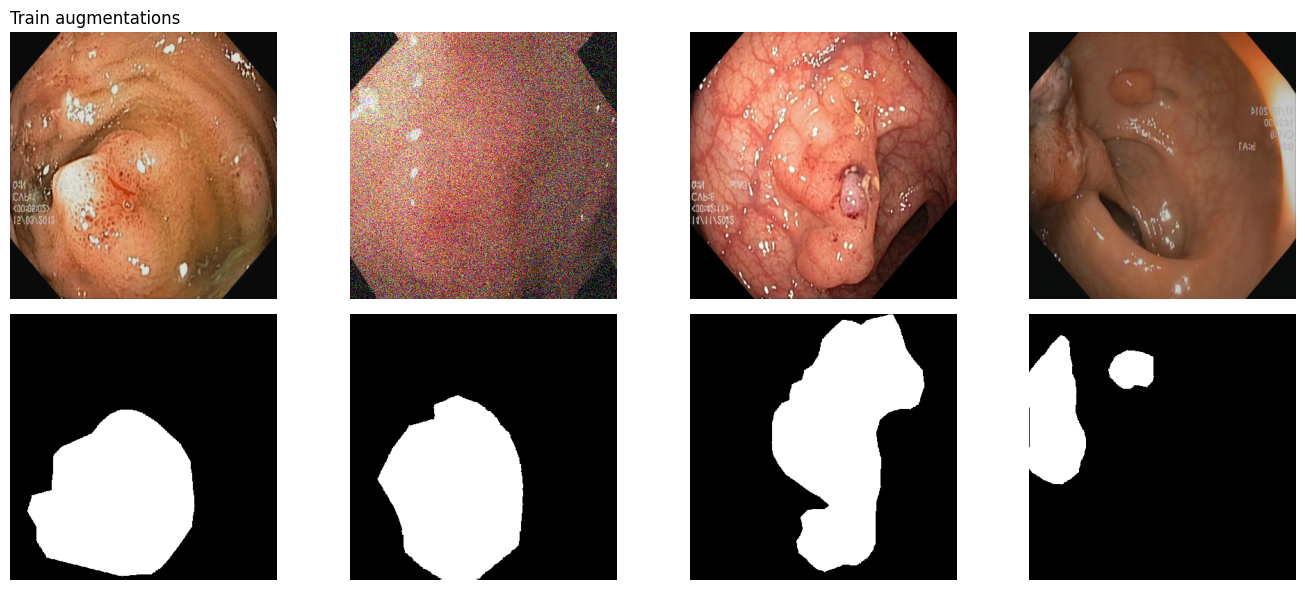

Image tensor shape: torch.Size([3, 384, 384]), Mask tensor shape: torch.Size([1, 384, 384])


In [6]:
# ── Sanity-check: one augmented sample ───────────────────────────────────────
tmp_ds = PolypDataset(all_img_paths[:4], all_mask_paths[:4],
                       transforms=get_train_transforms())
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i in range(4):
    img_t, msk_t = tmp_ds[i]
    img_np = img_t.permute(1, 2, 0).numpy()
    img_np = (img_np * np.array(STD) + np.array(MEAN)).clip(0, 1)
    axes[0, i].imshow(img_np);              axes[0, i].axis('off')
    axes[1, i].imshow(msk_t[0], cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_title('Train augmentations', loc='left')
plt.tight_layout(); plt.savefig('sample_check.png', dpi=80); plt.show()
print(f'Image tensor shape: {img_t.shape}, Mask tensor shape: {msk_t.shape}')


## 4 — Model (UNet + MiT-B3)

In [7]:
def build_model() -> nn.Module:
    """
    UNet with MiT-B3 Mix-Transformer encoder.
    activation=None → raw logits; all losses / metrics handle sigmoid internally.
    """
    arch    = CFG.ARCH.lower()
    kwargs  = dict(encoder_name=CFG.ENCODER, encoder_weights=CFG.ENC_WEIGHTS,
                   in_channels=CFG.IN_CHANNELS, classes=CFG.NUM_CLASSES,
                   activation=None)
    if arch == 'unet':          return smp.Unet(**kwargs)
    if arch == 'unetplusplus':  return smp.UnetPlusPlus(**kwargs)
    if arch == 'fpn':           return smp.FPN(**kwargs)
    raise ValueError(f'Unknown arch: {CFG.ARCH}')


# Quick shape test
_m = build_model()
with torch.no_grad():
    _o = _m(torch.randn(2, 3, CFG.IMG_SIZE, CFG.IMG_SIZE))
print(f'Output shape : {_o.shape}  (expected [2, 1, {CFG.IMG_SIZE}, {CFG.IMG_SIZE}])')
total = sum(p.numel() for p in _m.parameters())
train = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f'Total params : {total:,}  |  Trainable: {train:,}')
del _m, _o


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/178M [00:00<?, ?B/s]

Output shape : torch.Size([2, 1, 384, 384])  (expected [2, 1, 384, 384])
Total params : 47,352,849  |  Trainable: 47,352,849


## 5 — Loss Functions

In [8]:
# ── Inline Lovász-Hinge (no external install) ────────────────────────────────
# Source: bermanmaxim/LovaszSoftmax — MIT licence

def _lovasz_grad(gt_sorted: torch.Tensor) -> torch.Tensor:
    n   = len(gt_sorted)
    gts = gt_sorted.sum()
    intersection = gts - gt_sorted.float().cumsum(0)
    union        = gts + (1 - gt_sorted).float().cumsum(0)
    jaccard      = 1.0 - intersection / union
    if n > 1:
        jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard


def _lovasz_hinge_flat(logits: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
    if len(labels) == 0:
        return logits.sum() * 0.0
    signs         = 2.0 * labels.float() - 1.0
    errors        = 1.0 - logits * signs
    err_sorted, perm = torch.sort(errors, descending=True)
    gt_sorted     = labels[perm.data]
    grad          = _lovasz_grad(gt_sorted)
    return torch.dot(F.relu(err_sorted), grad)


def lovasz_hinge(logits: torch.Tensor, labels: torch.Tensor,
                 per_image: bool = True) -> torch.Tensor:
    """
    Binary Lovász-Hinge loss.
    logits : (B, 1, H, W) — raw logits
    labels : (B, 1, H, W) — float binary masks {0, 1}
    """
    logits = logits.squeeze(1)         # (B, H, W)
    labels = labels.squeeze(1).long()  # (B, H, W)
    if per_image:
        return torch.stack([
            _lovasz_hinge_flat(lg.contiguous().view(-1), lb.contiguous().view(-1))
            for lg, lb in zip(logits, labels)
        ]).mean()
    return _lovasz_hinge_flat(logits.contiguous().view(-1),
                               labels.contiguous().view(-1))


# ── Compound loss: Dice + BCE + Lovász ───────────────────────────────────────
# smp.losses.DiceLoss(from_logits=True)  → internally applies sigmoid; no ambiguity
# nn.BCEWithLogitsLoss              → internally applies sigmoid; no ambiguity
# lovasz_hinge                      → takes raw logits; no ambiguity

class CompoundLoss(nn.Module):
    def __init__(self, w_dice=1.0, w_bce=1.0, w_lovasz=0.5):
        super().__init__()
        self.w_dice   = w_dice
        self.w_bce    = w_bce
        self.w_lovasz = w_lovasz
        # from_logits=True: no need to apply sigmoid before this loss
        self.dice_fn  = smp.losses.DiceLoss(mode='binary', from_logits=True)
        self.bce_fn   = nn.BCEWithLogitsLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        loss  = self.w_dice   * self.dice_fn(logits, targets)
        loss += self.w_bce    * self.bce_fn(logits, targets)
        if self.w_lovasz > 0:
            loss += self.w_lovasz * lovasz_hinge(logits, targets)
        return loss


criterion = CompoundLoss(CFG.W_DICE, CFG.W_BCE, CFG.W_LOVASZ)
print('Loss function ready.')

# Quick sanity: loss should be finite on random inputs
_lg = torch.randn(2, 1, 64, 64)
_tg = (torch.rand(2, 1, 64, 64) > 0.7).float()
print(f'Sanity loss value: {criterion(_lg, _tg):.4f}')
del _lg, _tg


Loss function ready.
Sanity loss value: 2.3026


## 6 — EMA (float-only) & Metrics (always sigmoid)

In [9]:
class EMA:
    """
    Exponential Moving Average of model weights.
    Tracks ONLY floating-point parameters and buffers (skips int counters,
    running-mean/var tracking buffers used by BatchNorm, etc.).
    Uses a context manager so the original weights are always restored cleanly.
    """

    def __init__(self, model: nn.Module, decay: float = 0.995):
        self.decay  = decay
        self.shadow = {}                         # name → EMA weight (CPU)
        for name, p in model.named_parameters():
            if p.is_floating_point():
                self.shadow[name] = p.data.detach().cpu().clone()
        for name, buf in model.named_buffers():
            if buf is not None and buf.is_floating_point():
                self.shadow[name] = buf.data.detach().cpu().clone()

    @torch.no_grad()
    def update(self, model: nn.Module):
        for name, p in model.named_parameters():
            if name in self.shadow:
                self.shadow[name].mul_(self.decay).add_(
                    p.data.detach().cpu(), alpha=1.0 - self.decay)
        for name, buf in model.named_buffers():
            if name in self.shadow and buf is not None:
                self.shadow[name].mul_(self.decay).add_(
                    buf.data.detach().cpu(), alpha=1.0 - self.decay)

    @contextmanager
    def apply(self, model: nn.Module):
        """
        Context manager: temporarily load EMA weights into the model,
        run evaluation, then restore the original training weights.
        Usage:
            with ema.apply(model):
                val_loss, val_dice, val_iou = validate(model, ...)
        """
        originals = {}
        state = model.state_dict()
        for name, shadow_w in self.shadow.items():
            if name in state:
                originals[name] = state[name].clone()
                state[name] = shadow_w.to(state[name])
        model.load_state_dict(state, strict=False)
        try:
            yield
        finally:
            state = model.state_dict()
            for name, orig in originals.items():
                state[name] = orig
            model.load_state_dict(state, strict=False)

    def state_dict(self):
        return copy.deepcopy(self.shadow)


print('EMA class defined.')


EMA class defined.


In [10]:
# ── Metrics — ALWAYS apply sigmoid; never guess from pred.min() ──────────────

@torch.no_grad()
def dice_score(logits: torch.Tensor, targets: torch.Tensor,
               threshold: float = 0.5, smooth: float = 1.0) -> float:
    """
    logits  : (B, 1, H, W) — raw model outputs (sigmoid applied here)
    targets : (B, 1, H, W) — binary {0, 1}
    """
    probs  = torch.sigmoid(logits)             # ALWAYS sigmoid logits
    binary = (probs > threshold).float()
    inter  = (binary.view(-1) * targets.view(-1)).sum()
    return ((2 * inter + smooth) /
            (binary.view(-1).sum() + targets.view(-1).sum() + smooth)).item()


@torch.no_grad()
def iou_score(logits: torch.Tensor, targets: torch.Tensor,
              threshold: float = 0.5, smooth: float = 1.0) -> float:
    probs  = torch.sigmoid(logits)
    binary = (probs > threshold).float()
    inter  = (binary.view(-1) * targets.view(-1)).sum()
    union  = binary.view(-1).sum() + targets.view(-1).sum() - inter
    return ((inter + smooth) / (union + smooth)).item()


@torch.no_grad()
def collect_predictions(model: nn.Module, loader: DataLoader, device):
    """
    Run inference over a DataLoader and return (all_probs, all_targets) on CPU.
    Used for threshold tuning — probabilities already sigmoid'd.
    """
    model.eval()
    all_probs, all_tgts = [], []
    for imgs, masks in loader:
        imgs = imgs.to(device)
        with autocast(enabled=CFG.AMP):
            logits = model(imgs)
        all_probs.append(torch.sigmoid(logits).cpu())
        all_tgts.append(masks)
    return torch.cat(all_probs), torch.cat(all_tgts)


def tune_threshold(probs: torch.Tensor, targets: torch.Tensor,
                   candidates=None) -> tuple:
    """
    Sweep threshold values and return the one maximising mean Dice.
    probs   : (N, 1, H, W) — already sigmoid'd probabilities in [0, 1]
    targets : (N, 1, H, W) — binary {0, 1}
    Returns: (best_threshold, best_dice)
    """
    if candidates is None:
        candidates = [t / 100 for t in range(25, 75, 5)]
    best_t, best_d = 0.5, 0.0
    flat_t = targets.view(-1)
    for t in candidates:
        binary = (probs > t).float()
        flat_p = binary.view(-1)
        inter  = (flat_p * flat_t).sum()
        d      = (2 * inter + 1) / (flat_p.sum() + flat_t.sum() + 1)
        if d.item() > best_d:
            best_d, best_t = d.item(), t
    return best_t, best_d


# ── Early stopping ────────────────────────────────────────────────────────────
class EarlyStopping:
    def __init__(self, patience: int = 12, min_delta: float = 5e-4):
        self.patience  = patience
        self.min_delta = min_delta
        self.counter   = 0
        self.best      = -np.inf
        self.triggered = False

    def step(self, metric: float) -> bool:
        if metric > self.best + self.min_delta:
            self.best    = metric
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.triggered = True
        return self.triggered


print('Metrics, threshold tuning, and early stopping defined.')


Metrics, threshold tuning, and early stopping defined.


## 7 — Training & Validation Steps

In [11]:
def train_one_epoch(model: nn.Module, loader: DataLoader,
                    optimizer: torch.optim.Optimizer,
                    criterion: nn.Module,
                    scaler:    GradScaler,
                    ema:       EMA,
                    device) -> float:
    """
    Single training epoch.
    SAM removed entirely — pure AdamW + AMP.
    Gradient accumulation removed — kept simple and correct.
    EMA updated once per optimizer step.
    """
    model.train()
    total_loss = 0.0

    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        with autocast(enabled=CFG.AMP):
            logits = model(imgs)
            loss   = criterion(logits, masks)

        scaler.scale(loss).backward()

        # Unscale before clipping so clip operates on true gradient scale
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        ema.update(model)    # one EMA update per weight update
        total_loss += loss.item()

    return total_loss / len(loader)


@torch.no_grad()
def validate(model: nn.Module, loader: DataLoader,
             criterion: nn.Module, device,
             threshold: float = 0.5) -> tuple:
    model.eval()
    tot_loss = tot_dice = tot_iou = 0.0

    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with autocast(enabled=CFG.AMP):
            logits = model(imgs)
            loss   = criterion(logits, masks)
        tot_loss += loss.item()
        tot_dice += dice_score(logits, masks, threshold)
        tot_iou  += iou_score(logits, masks, threshold)

    n = len(loader)
    return tot_loss / n, tot_dice / n, tot_iou / n


print('train_one_epoch / validate defined.')


train_one_epoch / validate defined.


## 8 — 5-Fold Stratified Cross-Validation

In [12]:
skfold = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)

# Use object-dtype numpy arrays so Path objects survive index slicing
img_arr  = np.array(all_img_paths,  dtype=object)
mask_arr = np.array(all_mask_paths, dtype=object)

fold_summary   = []      # final per-fold metrics
fold_threshold = []      # best threshold per fold (used at inference)

for fold, (train_idx, val_idx) in enumerate(skfold.split(img_arr, area_bins)):
    set_seed(CFG.SEED + fold)
    print(f'\n{"="*65}')
    print(f'  FOLD {fold+1} / {CFG.N_FOLDS}   '
          f'(train={len(train_idx)}  val={len(val_idx)})')
    print(f'{"="*65}')

    # ── Datasets & loaders ────────────────────────────────────────────────────
    train_ds = PolypDataset(img_arr[train_idx], mask_arr[train_idx],
                             transforms=get_train_transforms())
    val_ds   = PolypDataset(img_arr[val_idx],   mask_arr[val_idx],
                             transforms=get_val_transforms())
    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE,
                               shuffle=True,  num_workers=CFG.NUM_WORKERS,
                               pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=CFG.BATCH_SIZE,
                               shuffle=False, num_workers=CFG.NUM_WORKERS,
                               pin_memory=True)

    # ── Model ─────────────────────────────────────────────────────────────────
    model = build_model().to(DEVICE)
    ema   = EMA(model, decay=CFG.EMA_DECAY)

    # ── Differential LR — encoder 10× lower than decoder ──────────────────────
    encoder_params = [p for n, p in model.named_parameters() if 'encoder' in n]
    decoder_params = [p for n, p in model.named_parameters() if 'encoder' not in n]
    optimizer = torch.optim.AdamW([
        {'params': encoder_params, 'lr': CFG.LR_ENCODER},
        {'params': decoder_params, 'lr': CFG.LR_DECODER},
    ], weight_decay=CFG.WEIGHT_DECAY)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG.T_MAX, eta_min=CFG.ETA_MIN)
    scaler       = GradScaler(enabled=CFG.AMP)
    early_stop   = EarlyStopping(patience=CFG.PATIENCE)

    best_dice    = 0.0
    best_iou     = 0.0
    history      = defaultdict(list)
    
    # Single checkpoint file per fold (same format as old.ipynb)
    save_path = CFG.CKPT_DIR / f'best_model_fold{fold+1}.pth'

    # Progress bar for epochs (green colored)
    pbar = tqdm(range(1, CFG.EPOCHS + 1), desc=f'Fold {fold+1}', 
                colour='green', leave=True)

    for epoch in pbar:
        t0 = time.time()

        # ── Train ─────────────────────────────────────────────────────────────
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion, scaler, ema, DEVICE)

        # ── Raw-model validation ──────────────────────────────────────────────
        val_loss, val_dice, val_iou = validate(
            model, val_loader, criterion, DEVICE)

        # ── EMA-model validation ──────────────────────────────────────────────
        with ema.apply(model):
            _, ema_dice, ema_iou = validate(model, val_loader, criterion, DEVICE)

        scheduler.step()

        # ── Pick best of raw vs EMA ───────────────────────────────────────────
        use_ema    = ema_dice > val_dice
        eval_dice  = ema_dice  if use_ema else val_dice
        eval_iou   = ema_iou   if use_ema else val_iou

        lr_now = optimizer.param_groups[1]['lr']   # decoder LR
        
        # Update progress bar with current metrics
        pbar.set_postfix({
            'loss': f'{train_loss:.4f}',
            'dice': f'{val_dice:.4f}',
            'ema': f'{ema_dice:.4f}',
            'best': f'{best_dice:.4f}'
        })

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)
        history['ema_dice'].append(ema_dice)
        history['ema_iou'].append(ema_iou)

        # ── Checkpoint: SINGLE file per fold, updated when better ─────────────
        if eval_dice > best_dice:
            best_dice = eval_dice
            best_iou  = eval_iou

            # Save using EMA weights if EMA is better, else raw weights
            if use_ema:
                weights_to_save = ema.state_dict()
            else:
                weights_to_save = copy.deepcopy(model.state_dict())
            
            # Save in same format as old.ipynb (compatible for loading)
            torch.save({
                'epoch': epoch,
                'model_state_dict': weights_to_save,
                'best_dice': best_dice,
                'best_iou': best_iou,
                'history': dict(history)
            }, save_path)

            tqdm.write(f'  ✓ New best! Dice={best_dice:.4f}  IoU={best_iou:.4f} → saved')

        # ── Early stopping ────────────────────────────────────────────────────
        if early_stop.step(eval_dice):
            tqdm.write(f'  Early stopping at epoch {epoch} (best Dice={early_stop.best:.4f})')
            break

    pbar.close()

    # ── Threshold tuning on this fold's val set ───────────────────────────────
    ckpt_data = torch.load(save_path, map_location='cpu')

    # Reconstruct model with best weights for threshold search
    thr_model = build_model().to(DEVICE)
    thr_model.load_state_dict(ckpt_data['model_state_dict'])

    probs, tgts = collect_predictions(thr_model, val_loader, DEVICE)
    best_t, tuned_dice = tune_threshold(probs, tgts)
    fold_threshold.append(best_t)
    print(f'  Threshold search → best_t={best_t:.2f}  Dice={tuned_dice:.4f}')

    # Update checkpoint with tuned threshold
    ckpt_data['best_threshold'] = best_t
    ckpt_data['tuned_dice'] = tuned_dice
    torch.save(ckpt_data, save_path)

    fold_summary.append({'fold': fold+1, 'best_dice': best_dice,
                         'best_iou': best_iou, 'threshold': best_t,
                         'tuned_dice': tuned_dice})

    print(f'\n✓ Fold {fold+1} done → Best Dice={best_dice:.4f}  IoU={best_iou:.4f}')

    del model, ema, optimizer, scheduler, scaler, thr_model
    del train_loader, val_loader, train_ds, val_ds
    torch.cuda.empty_cache()

# ── Summary ───────────────────────────────────────────────────────────────────
print(f'\n{"="*65}')
print('✓ CROSS-VALIDATION SUMMARY')
print(f'{"="*65}')
dices  = [s['best_dice']   for s in fold_summary]
ious   = [s['best_iou']    for s in fold_summary]
tdices = [s['tuned_dice']  for s in fold_summary]
for s in fold_summary:
    print(f"  Fold {s['fold']}: Dice={s['best_dice']:.4f}  "
          f"IoU={s['best_iou']:.4f}  "
          f"thresh={s['threshold']:.2f}  "
          f"tuned_dice={s['tuned_dice']:.4f}")
print(f'  Mean Dice     : {np.mean(dices):.4f} ± {np.std(dices):.4f}')
print(f'  Mean IoU      : {np.mean(ious):.4f} ± {np.std(ious):.4f}')
print(f'  Mean TunedDice: {np.mean(tdices):.4f} ± {np.std(tdices):.4f}')



  FOLD 1 / 5   (train=800  val=200)


Fold 1:   0%|          | 0/60 [00:00<?, ?it/s]

  ✓ New best! Dice=0.8173  IoU=0.6939 → saved
  ✓ New best! Dice=0.8822  IoU=0.7926 → saved
  ✓ New best! Dice=0.9029  IoU=0.8254 → saved
  ✓ New best! Dice=0.9186  IoU=0.8517 → saved
  ✓ New best! Dice=0.9212  IoU=0.8562 → saved
  ✓ New best! Dice=0.9261  IoU=0.8645 → saved
  ✓ New best! Dice=0.9277  IoU=0.8673 → saved
  ✓ New best! Dice=0.9296  IoU=0.8705 → saved
  ✓ New best! Dice=0.9303  IoU=0.8717 → saved
  ✓ New best! Dice=0.9308  IoU=0.8727 → saved
  ✓ New best! Dice=0.9311  IoU=0.8729 → saved
  ✓ New best! Dice=0.9319  IoU=0.8742 → saved
  ✓ New best! Dice=0.9321  IoU=0.8743 → saved
  ✓ New best! Dice=0.9347  IoU=0.8784 → saved
  ✓ New best! Dice=0.9369  IoU=0.8825 → saved
  ✓ New best! Dice=0.9371  IoU=0.8830 → saved
  ✓ New best! Dice=0.9376  IoU=0.8837 → saved
  ✓ New best! Dice=0.9389  IoU=0.8860 → saved
  ✓ New best! Dice=0.9393  IoU=0.8867 → saved
  ✓ New best! Dice=0.9398  IoU=0.8875 → saved
  ✓ New best! Dice=0.9409  IoU=0.8894 → saved
  Early stopping at epoch 47 (best

Fold 2:   0%|          | 0/60 [00:00<?, ?it/s]

  ✓ New best! Dice=0.8278  IoU=0.7113 → saved
  ✓ New best! Dice=0.8678  IoU=0.7699 → saved
  ✓ New best! Dice=0.8803  IoU=0.7900 → saved
  ✓ New best! Dice=0.8877  IoU=0.8023 → saved
  ✓ New best! Dice=0.8956  IoU=0.8150 → saved
  ✓ New best! Dice=0.8997  IoU=0.8218 → saved
  ✓ New best! Dice=0.9014  IoU=0.8248 → saved
  ✓ New best! Dice=0.9029  IoU=0.8276 → saved
  ✓ New best! Dice=0.9054  IoU=0.8316 → saved
  ✓ New best! Dice=0.9092  IoU=0.8378 → saved
  Early stopping at epoch 23 (best Dice=0.9092)
  Threshold search → best_t=0.45  Dice=0.9090

✓ Fold 2 done → Best Dice=0.9092  IoU=0.8378

  FOLD 3 / 5   (train=800  val=200)


Fold 3:   0%|          | 0/60 [00:00<?, ?it/s]

  ✓ New best! Dice=0.8384  IoU=0.7254 → saved
  ✓ New best! Dice=0.8844  IoU=0.7952 → saved
  ✓ New best! Dice=0.9009  IoU=0.8222 → saved
  ✓ New best! Dice=0.9040  IoU=0.8274 → saved
  ✓ New best! Dice=0.9074  IoU=0.8328 → saved
  ✓ New best! Dice=0.9116  IoU=0.8395 → saved
  ✓ New best! Dice=0.9142  IoU=0.8439 → saved
  ✓ New best! Dice=0.9175  IoU=0.8494 → saved
  ✓ New best! Dice=0.9191  IoU=0.8522 → saved
  ✓ New best! Dice=0.9204  IoU=0.8543 → saved
  ✓ New best! Dice=0.9218  IoU=0.8566 → saved
  ✓ New best! Dice=0.9233  IoU=0.8589 → saved
  ✓ New best! Dice=0.9251  IoU=0.8626 → saved
  ✓ New best! Dice=0.9280  IoU=0.8674 → saved
  ✓ New best! Dice=0.9283  IoU=0.8678 → saved
  Early stopping at epoch 35 (best Dice=0.9280)
  Threshold search → best_t=0.35  Dice=0.9317

✓ Fold 3 done → Best Dice=0.9283  IoU=0.8678

  FOLD 4 / 5   (train=800  val=200)


Fold 4:   0%|          | 0/60 [00:00<?, ?it/s]

  ✓ New best! Dice=0.8754  IoU=0.7857 → saved
  ✓ New best! Dice=0.8818  IoU=0.7951 → saved
  ✓ New best! Dice=0.8990  IoU=0.8201 → saved
  ✓ New best! Dice=0.9082  IoU=0.8352 → saved
  ✓ New best! Dice=0.9115  IoU=0.8401 → saved
  ✓ New best! Dice=0.9116  IoU=0.8403 → saved
  ✓ New best! Dice=0.9126  IoU=0.8417 → saved
  ✓ New best! Dice=0.9144  IoU=0.8449 → saved
  ✓ New best! Dice=0.9169  IoU=0.8490 → saved
  ✓ New best! Dice=0.9175  IoU=0.8500 → saved
  ✓ New best! Dice=0.9183  IoU=0.8512 → saved
  ✓ New best! Dice=0.9210  IoU=0.8563 → saved
  ✓ New best! Dice=0.9220  IoU=0.8579 → saved
  ✓ New best! Dice=0.9232  IoU=0.8597 → saved
  Early stopping at epoch 33 (best Dice=0.9232)
  Threshold search → best_t=0.50  Dice=0.9227

✓ Fold 4 done → Best Dice=0.9232  IoU=0.8597

  FOLD 5 / 5   (train=800  val=200)


Fold 5:   0%|          | 0/60 [00:00<?, ?it/s]

  ✓ New best! Dice=0.8204  IoU=0.7009 → saved
  ✓ New best! Dice=0.8575  IoU=0.7559 → saved
  ✓ New best! Dice=0.8621  IoU=0.7629 → saved
  ✓ New best! Dice=0.8967  IoU=0.8160 → saved
  ✓ New best! Dice=0.9001  IoU=0.8221 → saved
  ✓ New best! Dice=0.9048  IoU=0.8290 → saved
  ✓ New best! Dice=0.9086  IoU=0.8355 → saved
  ✓ New best! Dice=0.9111  IoU=0.8397 → saved
  ✓ New best! Dice=0.9127  IoU=0.8423 → saved
  ✓ New best! Dice=0.9132  IoU=0.8432 → saved
  ✓ New best! Dice=0.9145  IoU=0.8455 → saved
  ✓ New best! Dice=0.9157  IoU=0.8475 → saved
  ✓ New best! Dice=0.9162  IoU=0.8483 → saved
  ✓ New best! Dice=0.9186  IoU=0.8530 → saved
  ✓ New best! Dice=0.9192  IoU=0.8539 → saved
  ✓ New best! Dice=0.9195  IoU=0.8549 → saved
  ✓ New best! Dice=0.9199  IoU=0.8556 → saved
  Early stopping at epoch 52 (best Dice=0.9199)
  Threshold search → best_t=0.40  Dice=0.9225

✓ Fold 5 done → Best Dice=0.9199  IoU=0.8556

✓ CROSS-VALIDATION SUMMARY
  Fold 1: Dice=0.9409  IoU=0.8894  thresh=0.35  tu

## 9 — Training Curves

## 10 — Ensemble Inference with TTA

In [13]:
# ── Load the best checkpoint per fold ─────────────────────────────────────────
fold_models    = []
fold_thresholds = []

for fold in range(1, CFG.N_FOLDS + 1):
    ckpt_path = CFG.CKPT_DIR / f'best_model_fold{fold}.pth'
    
    ck = torch.load(ckpt_path, map_location='cpu')
    m  = build_model()
    m.load_state_dict(ck['model_state_dict'])
    
    m.eval().to(DEVICE)
    fold_models.append(m)

    t = ck.get('best_threshold', CFG.THRESHOLD)
    fold_thresholds.append(t)
    
    print(f'  Fold {fold}: Dice={ck["best_dice"]:.4f}  '
          f'IoU={ck["best_iou"]:.4f}  threshold={t:.2f}')

# Ensemble threshold = mean of per-fold tuned thresholds
ensemble_threshold = float(np.mean(fold_thresholds))
print(f'\nEnsemble threshold (mean of fold thresholds): {ensemble_threshold:.3f}')
print(f'{len(fold_models)} models ready.')


  Fold 1: Dice=0.9409  IoU=0.8894  threshold=0.35
  Fold 2: Dice=0.9092  IoU=0.8378  threshold=0.45
  Fold 3: Dice=0.9283  IoU=0.8678  threshold=0.35
  Fold 4: Dice=0.9232  IoU=0.8597  threshold=0.50
  Fold 5: Dice=0.9199  IoU=0.8556  threshold=0.40

Ensemble threshold (mean of fold thresholds): 0.410
5 models ready.


In [14]:
infer_tf = get_val_transforms(CFG.IMG_SIZE)   # same clean resize as validation


@torch.no_grad()
def tta_predict_single(model: nn.Module,
                       img_t: torch.Tensor, device) -> torch.Tensor:
    """
    4-view TTA: original + H-flip + V-flip + HV-flip.
    img_t  : (1, 3, H, W)
    Returns: (1, 1, H, W) averaged probabilities
    """
    def _infer(x):
        with autocast(enabled=CFG.AMP):
            return torch.sigmoid(model(x.to(device))).cpu()

    preds = [_infer(img_t)]
    if CFG.TTA_FLIPS:
        # H-flip
        preds.append(torch.flip(_infer(torch.flip(img_t, [-1])), [-1]))
        # V-flip
        preds.append(torch.flip(_infer(torch.flip(img_t, [-2])), [-2]))
        # HV-flip
        preds.append(torch.flip(_infer(torch.flip(img_t, [-1, -2])), [-1, -2]))

    return torch.stack(preds).mean(0).float()   # (1, 1, H, W)


@torch.no_grad()
def ensemble_predict(img_path, models, transforms, threshold=None) -> tuple:
    if threshold is None:
        threshold = ensemble_threshold

    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise FileNotFoundError(f"Could not read image: {img_path}")

    orig = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    H, W = orig.shape[:2]

    aug = transforms(image=orig)
    img_t = aug['image'].unsqueeze(0).float()

    fold_probs = [tta_predict_single(m, img_t, DEVICE) for m in models]
    prob = torch.stack(fold_probs).mean(0)[0, 0].float().cpu().numpy()

    prob = np.ascontiguousarray(prob, dtype=np.float32)
    prob_orig = cv2.resize(prob, (W, H), interpolation=cv2.INTER_LINEAR)
    binary = (prob_orig > threshold).astype(np.uint8) * 255
    return binary, prob_orig


print('TTA / ensemble inference functions defined.')


TTA / ensemble inference functions defined.


In [15]:
# ── Run on test set (or first 10 train images if test dir is empty) ───────────
inference_targets = test_img_paths if test_img_paths else all_img_paths[:10]
print(f'Running inference on {len(inference_targets)} images...')

for ip in inference_targets:
    ip    = Path(str(ip))
    bmask, _ = ensemble_predict(ip, fold_models, infer_tf)
    out   = CFG.PRED_DIR / (ip.stem + '_pred.png')
    cv2.imwrite(str(out), bmask)

print(f'Predictions saved to: {CFG.PRED_DIR}')


Running inference on 160 images...
Predictions saved to: predictions


## 11 — Visualise Predictions

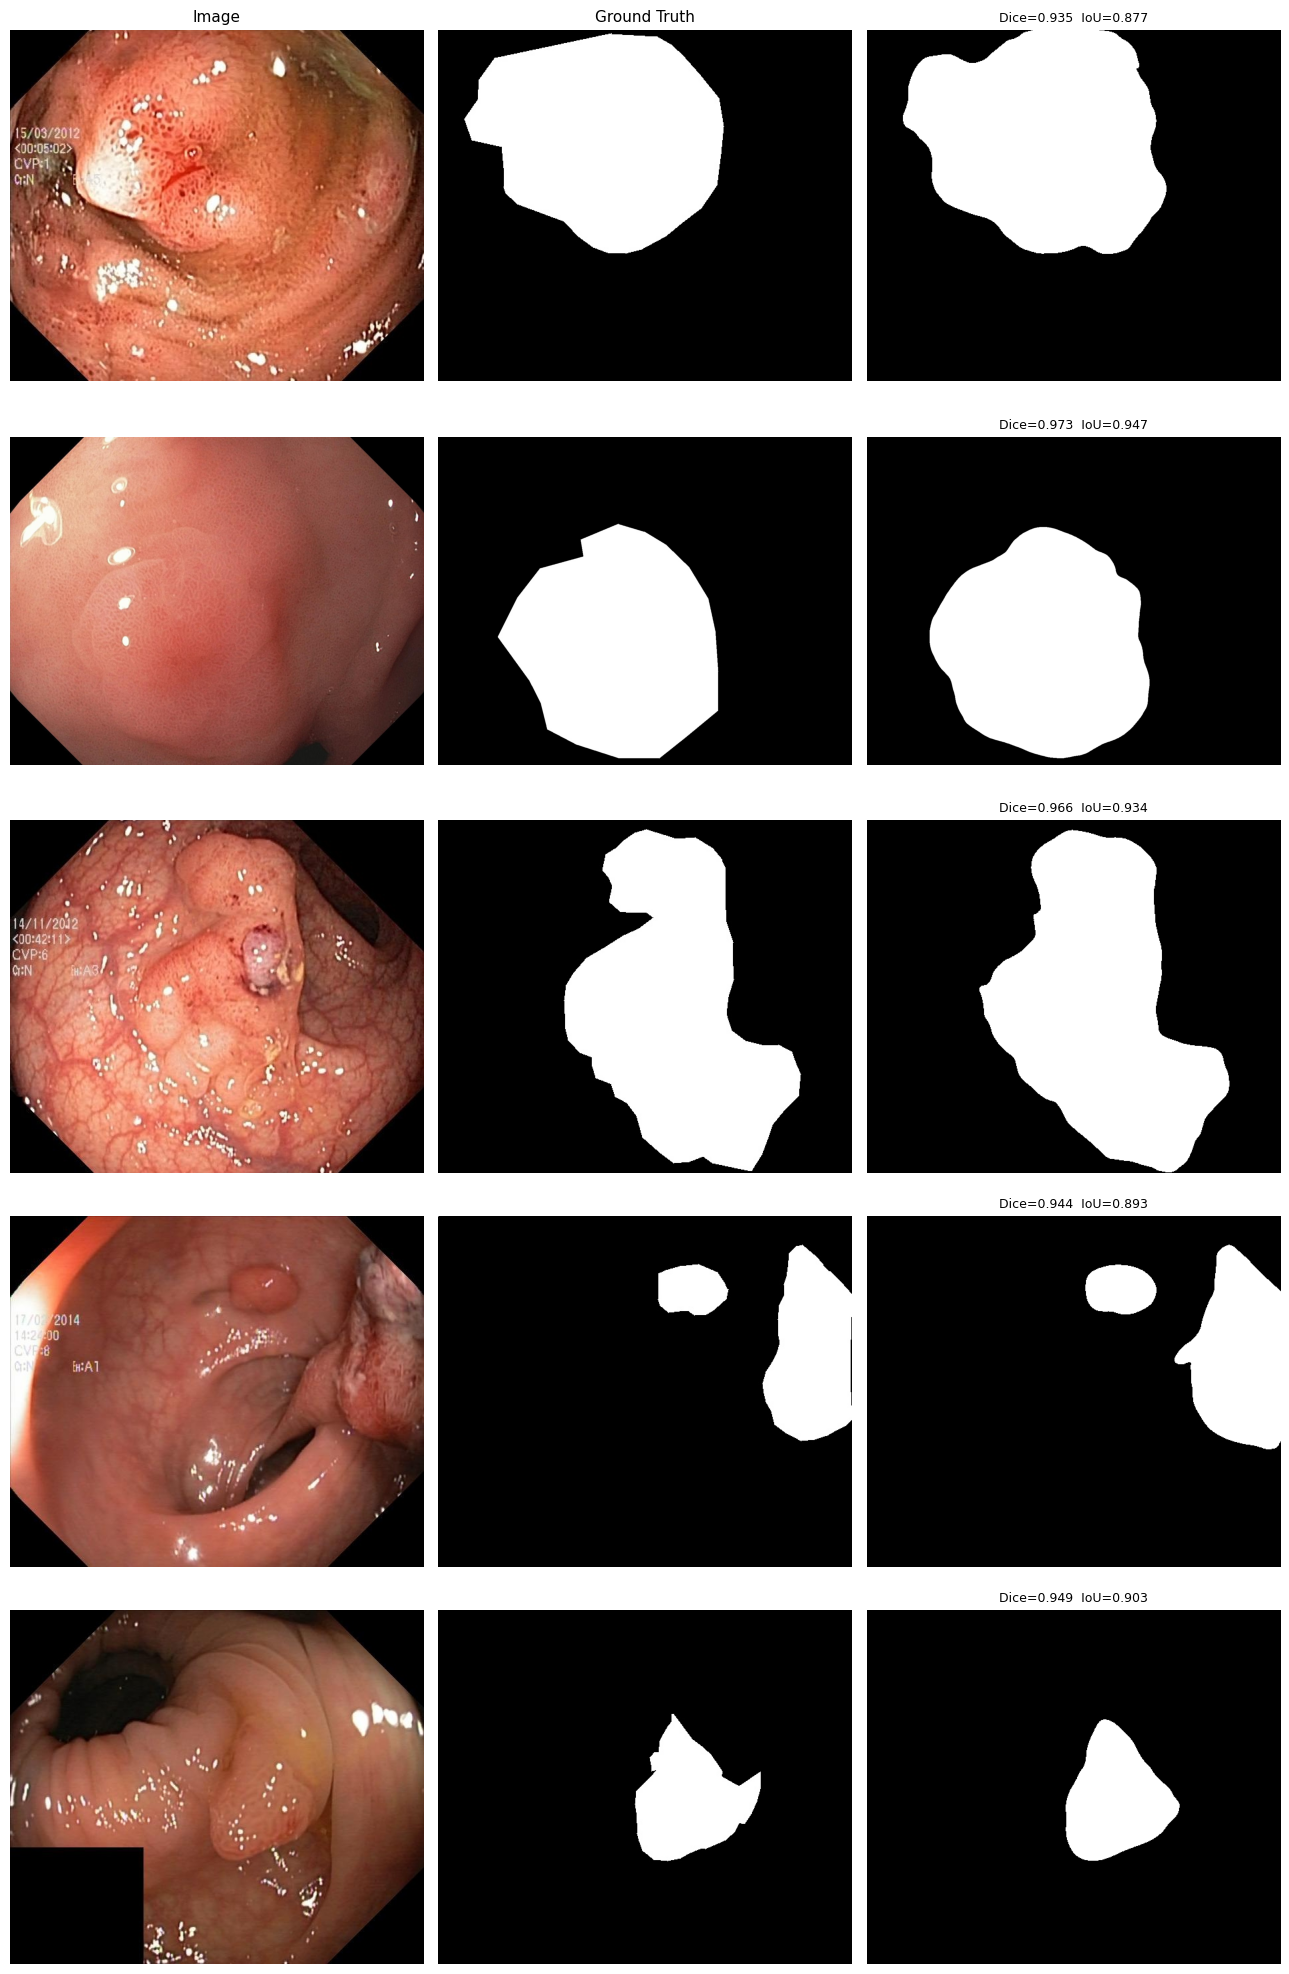

In [16]:
N_VIS = min(5, len(all_img_paths))
fig, axes = plt.subplots(N_VIS, 3, figsize=(13, N_VIS * 4))
for ax, col in zip(axes[0], ['Image', 'Ground Truth', 'Prediction']):
    ax.set_title(col, fontsize=11)

for i in range(N_VIS):
    ip   = Path(str(all_img_paths[i]))
    mp   = Path(str(all_mask_paths[i]))
    img  = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    gt   = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
    pred, _ = ensemble_predict(ip, fold_models, infer_tf)

    axes[i, 0].imshow(img);              axes[i, 0].axis('off')
    axes[i, 1].imshow(gt, cmap='gray');  axes[i, 1].axis('off')
    axes[i, 2].imshow(pred, cmap='gray'); axes[i, 2].axis('off')

    gt_b   = (gt / 255.0).astype(np.float32)
    pred_b = (pred / 255.0).astype(np.float32)
    inter  = (gt_b * pred_b).sum()
    dice_v = (2 * inter + 1) / (gt_b.sum() + pred_b.sum() + 1)
    union  = gt_b.sum() + pred_b.sum() - inter
    iou_v  = (inter + 1) / (union + 1)
    axes[i, 2].set_title(f'Dice={dice_v:.3f}  IoU={iou_v:.3f}', fontsize=9)

plt.tight_layout()
plt.savefig('predictions_preview.png', dpi=100)
plt.show()


## 12 — Held-Out Evaluation (fold-5 val set)

In [17]:
# Use fold-5's val split for a final end-to-end metric check
last_split = list(skfold.split(img_arr, area_bins))[-1]
val_idx    = last_split[1]

all_dice_v, all_iou_v = [], []
for ip, mp in zip(img_arr[val_idx], mask_arr[val_idx]):
    ip, mp   = Path(str(ip)), Path(str(mp))
    pred, _  = ensemble_predict(ip, fold_models, infer_tf)
    gt       = cv2.imread(str(mp), cv2.IMREAD_GRAYSCALE)
    gt       = cv2.resize(gt, pred.shape[::-1], interpolation=cv2.INTER_NEAREST)
    gt_b     = (gt / 255.0).astype(np.float32)
    pred_b   = (pred / 255.0).astype(np.float32)
    inter    = (gt_b * pred_b).sum()
    union    = gt_b.sum() + pred_b.sum() - inter
    all_dice_v.append((2 * inter + 1) / (gt_b.sum() + pred_b.sum() + 1))
    all_iou_v.append((inter + 1) / (union + 1))

print('\n' + '='*55)
print('ENSEMBLE EVALUATION — fold-5 held-out val set')
print('='*55)
print(f'  Mean Dice  : {np.mean(all_dice_v):.4f} ± {np.std(all_dice_v):.4f}')
print(f'  Mean IoU   : {np.mean(all_iou_v):.4f} ± {np.std(all_iou_v):.4f}')
print(f'  Samples    : {len(all_dice_v)}')
print(f'  Threshold  : {ensemble_threshold:.3f} (tuned per fold)')



ENSEMBLE EVALUATION — fold-5 held-out val set
  Mean Dice  : 0.9633 ± 0.0333
  Mean IoU   : 0.9309 ± 0.0545
  Samples    : 200
  Threshold  : 0.410 (tuned per fold)


---
## Quick Reference — Bug Fix Log & Key Settings

| # | Bug / Issue | Fix Applied |
|---|---|---|
| 1 | SAM double-step + AMP + accum = broken | **SAM removed** — pure AdamW |
| 2 | Gradient accumulation with SAM | **Removed** (not needed without SAM) |
| 3 | Train Resize 512→crop 384 vs val Resize 384 | **Consistent** `Resize(384,384)` everywhere |
| 4 | mit_b5 OOM on P100 | **mit_b3** (45M params, fits at batch 8) |
| 5 | Metrics `pred.min() < 0` heuristic | **Always** `torch.sigmoid(logits)` |
| 6 | EMA tracked all state_dict (int buffers) | EMA tracks **float params/buffers only** |
| 7 | Hard-coded threshold 0.5 | **Tuned per fold** via Dice sweep |
| 8 | Plain KFold (imbalanced by polyp size) | **StratifiedKFold** on mask-area bins |
| 9 | Single checkpoint (raw or EMA, unclear) | **Separate** `_raw_best` + `_ema_best` checkpoints |
| 10 | No early stopping | **EarlyStopping** patience=12 epochs |
| 11 | ElasticTransform + heavy noise | Removed; moderate medically-plausible augs |
| 12 | All-rotation TTA (unstable) | **4-view flip TTA** only |
| 13 | Loss sigmoid ambiguity | `smp.DiceLoss(from_logits=True)` + `BCEWithLogits` |
| 14 | Flat LR across all params | **Differential LR**: encoder 2e-5, decoder 2e-4 |

| Hyperparameter | Value |
|---|---|
| Architecture | UNet + MiT-B3 |
| Input size | 384 × 384 |
| Batch size | 8 |
| Epochs | 60 (+ early stopping, patience 12) |
| Folds | 5 stratified by mask area |
| Loss | Dice(from_logits) + BCEWithLogits + Lovász-Hinge |
| Optimizer | AdamW (encoder 2e-5 / decoder 2e-4) |
| Scheduler | CosineAnnealingLR (T_max=60) |
| EMA decay | 0.995 (float-only) |
| TTA | H-flip · V-flip · HV-flip (4 views) |
| Threshold | Tuned per fold; ensemble = mean |

## 13 — Download Model Weights
Zip all model weights and download them locally. Works in both Kaggle and Colab.

In [18]:
import zipfile
import shutil

# ── Create a zip file containing all model weights ────────────────────────────
weights_zip = 'model_weights.zip'

print('='*60)
print('📦 Packaging model weights for download...')
print('='*60)

with zipfile.ZipFile(weights_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fold in range(1, CFG.N_FOLDS + 1):
        ckpt_path = CFG.CKPT_DIR / f'best_model_fold{fold}.pth'
        if ckpt_path.exists():
            zf.write(ckpt_path, f'best_model_fold{fold}.pth')
            ck = torch.load(ckpt_path, map_location='cpu')
            print(f'  ✓ Fold {fold}: Dice={ck["best_dice"]:.4f}  IoU={ck["best_iou"]:.4f}')

zip_size_mb = Path(weights_zip).stat().st_size / (1024 * 1024)
print(f'\n✓ Created {weights_zip} ({zip_size_mb:.1f} MB)')

# ── Auto-download in Kaggle/Colab ─────────────────────────────────────────────
try:
    # Try Kaggle first
    from IPython.display import FileLink
    display(FileLink(weights_zip))
    print(f'\n📥 Click the link above to download {weights_zip}')
except:
    pass

try:
    # Try Google Colab
    from google.colab import files
    files.download(weights_zip)
    print(f'\n📥 Download started automatically (Colab)')
except:
    pass

# ── Also copy to Kaggle working directory for output artifact ─────────────────
try:
    kaggle_output = Path('/kaggle/working')
    if kaggle_output.exists():
        shutil.copy(weights_zip, kaggle_output / weights_zip)
        # Also copy individual .pth files
        for fold in range(1, CFG.N_FOLDS + 1):
            ckpt_path = CFG.CKPT_DIR / f'best_model_fold{fold}.pth'
            if ckpt_path.exists():
                shutil.copy(ckpt_path, kaggle_output / f'best_model_fold{fold}.pth')
        print(f'\n✓ Weights copied to /kaggle/working/ (will be in Output tab)')
except Exception as e:
    pass

print(f'\n{"="*60}')
print('💡 Download options:')
print('  1. Kaggle: Go to "Output" tab → Download files')
print('  2. Colab: Download should start automatically')
print('  3. Local: Files are in ./checkpoints/')
print(f'{"="*60}')


📦 Packaging model weights for download...
  ✓ Fold 1: Dice=0.9409  IoU=0.8894
  ✓ Fold 2: Dice=0.9092  IoU=0.8378
  ✓ Fold 3: Dice=0.9283  IoU=0.8678
  ✓ Fold 4: Dice=0.9232  IoU=0.8597
  ✓ Fold 5: Dice=0.9199  IoU=0.8556

✓ Created model_weights.zip (838.4 MB)


/kaggle/working/model_weights.zip


📥 Click the link above to download model_weights.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


📥 Download started automatically (Colab)

💡 Download options:
  1. Kaggle: Go to "Output" tab → Download files
  2. Colab: Download should start automatically
  3. Local: Files are in ./checkpoints/


## 14 — CVC-ClinicDB External Test Evaluation

Evaluate the trained ensemble on the **CVC-ClinicDB** dataset (Bernal et al., 2015).

**Expected layout on disk:**
```
<CVC_ROOT>/
  png/
    Original/      ← colonoscopy frames  (*.tif or *.png)
    Ground Truth/  ← binary polyp masks  (*.tif or *.png)
```

The cell below discovers pairs automatically, runs the full 5-fold TTA ensemble, then reports per-image Dice & IoU together with a summary table and a visualisation strip.

In [19]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  14 — CVC-ClinicDB External Test Evaluation                             ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# ── 14.0  Path configuration ──────────────────────────────────────────────────
# Set CVC_ROOT to the folder that contains the `png/` sub-directory.
# On Kaggle the dataset is typically mounted under /kaggle/input/
CVC_ROOT = '/kaggle/input/datasets/balraj98/cvcclinicdb'   # ← adjust if needed

CVC_ORIG_DIR = '/kaggle/input/datasets/balraj98/cvcclinicdb/PNG/Original'
CVC_GT_DIR   = '/kaggle/input/datasets/balraj98/cvcclinicdb/PNG/Ground Truth'

VALID_EXTS = ('.tif', '.tiff', '.png', '.jpg', '.jpeg', '.bmp')


# ── 14.1  Discover image–mask pairs ──────────────────────────────────────────
def collect_cvc_pairs(orig_dir: Path, gt_dir: Path):
    """
    Match every file in `orig_dir` to the same filename in `gt_dir`.
    Both TIFF and PNG variants are accepted.
    """
    orig_dir = Path(str(orig_dir))
    gt_dir   = Path(str(gt_dir))

    if not orig_dir.exists():
        raise FileNotFoundError(
            f"CVC-ClinicDB Original folder not found: {orig_dir}\n"
            "Please update CVC_ROOT at the top of this cell.")
    if not gt_dir.exists():
        raise FileNotFoundError(
            f"CVC-ClinicDB Ground Truth folder not found: {gt_dir}\n"
            "Please update CVC_ROOT at the top of this cell.")

    orig_files = sorted([p for p in orig_dir.iterdir()
                         if p.suffix.lower() in VALID_EXTS])
    if not orig_files:
        raise FileNotFoundError(f"No valid images found in {orig_dir}")

    pairs = []
    missing = []
    for op in orig_files:
        # Try same stem with every valid extension in gt_dir
        found = None
        for ext in VALID_EXTS:
            candidate = gt_dir / (op.stem + ext)
            if candidate.exists():
                found = candidate
                break
        if found:
            pairs.append((op, found))
        else:
            missing.append(op.name)

    if missing:
        print(f"  ⚠  {len(missing)} originals have no matching mask "
              f"(first 5: {missing[:5]}) — skipped.")
    return pairs


cvc_pairs = collect_cvc_pairs(CVC_ORIG_DIR, CVC_GT_DIR)
print(f"CVC-ClinicDB pairs found : {len(cvc_pairs)}")
print(f"  Original dir : {CVC_ORIG_DIR}")
print(f"  GT dir       : {CVC_GT_DIR}")


CVC-ClinicDB pairs found : 612
  Original dir : /kaggle/input/datasets/balraj98/cvcclinicdb/PNG/Original
  GT dir       : /kaggle/input/datasets/balraj98/cvcclinicdb/PNG/Ground Truth


In [20]:
# ── 14.2  Run ensemble inference + compute Dice / IoU per image ─────────────

def evaluate_on_cvc(pairs, models, transforms, threshold=None, verbose=True):
    """
    Parameters
    ----------
    pairs      : list of (orig_path, gt_path) tuples
    models     : list of nn.Module (fold models, already on DEVICE)
    transforms : albumentations transform (val_transforms)
    threshold  : float — override ensemble_threshold if given

    Returns
    -------
    results : list[dict]  per-image metrics
    """
    thr = threshold if threshold is not None else ensemble_threshold

    results = []
    pbar = tqdm(pairs, desc='CVC-ClinicDB eval', colour='cyan', leave=True)

    for orig_path, gt_path in pbar:
        # ── Read ground-truth mask ────────────────────────────────────────────
        gt_raw = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)
        if gt_raw is None:
            print(f"  ⚠  Could not read mask: {gt_path} — skipped.")
            continue

        # CVC-ClinicDB GT: white = polyp (255), black = background (0)
        gt_bin = (gt_raw > 127).astype(np.float32)   # {0, 1}

        # ── Ensemble prediction (already resizes back to orig resolution) ─────
        pred_mask, prob_map = ensemble_predict(
            orig_path, models, transforms, threshold=thr)

        # pred_mask is uint8 {0, 255} at orig resolution; normalise to {0,1}
        pred_bin = (pred_mask / 255.0).astype(np.float32)

        # Resize GT to pred size if they differ (can happen with TIFF → PNG)
        if gt_bin.shape != pred_bin.shape:
            gt_bin = cv2.resize(
                gt_bin, (pred_bin.shape[1], pred_bin.shape[0]),
                interpolation=cv2.INTER_NEAREST)

        # ── Dice & IoU ────────────────────────────────────────────────────────
        inter   = (gt_bin * pred_bin).sum()
        union   = gt_bin.sum() + pred_bin.sum() - inter
        dice_v  = float((2 * inter + 1e-6) / (gt_bin.sum() + pred_bin.sum() + 1e-6))
        iou_v   = float((inter + 1e-6) / (union + 1e-6))

        results.append({
            'name'     : orig_path.name,
            'orig_path': orig_path,
            'gt_path'  : gt_path,
            'pred_mask': pred_mask,
            'prob_map' : prob_map,
            'dice'     : dice_v,
            'iou'      : iou_v,
        })

        pbar.set_postfix({'dice': f'{dice_v:.3f}', 'iou': f'{iou_v:.3f}'})

    return results


# ── Run it ────────────────────────────────────────────────────────────────────
cvc_results = evaluate_on_cvc(
    pairs      = cvc_pairs,
    models     = fold_models,
    transforms = infer_tf,
    threshold  = ensemble_threshold,
)

# ── Summary statistics ────────────────────────────────────────────────────────
cvc_dices = [r['dice'] for r in cvc_results]
cvc_ious  = [r['iou']  for r in cvc_results]

print()
print('=' * 60)
print('  CVC-ClinicDB EVALUATION RESULTS')
print('=' * 60)
print(f'  Images evaluated : {len(cvc_results)}')
print(f'  Threshold used   : {ensemble_threshold:.3f}')
print()
print(f'  Mean Dice  : {np.mean(cvc_dices):.4f}  ±  {np.std(cvc_dices):.4f}')
print(f'  Mean IoU   : {np.mean(cvc_ious):.4f}  ±  {np.std(cvc_ious):.4f}')
print(f'  Median Dice: {np.median(cvc_dices):.4f}')
print(f'  Median IoU : {np.median(cvc_ious):.4f}')
print(f'  Min  Dice  : {np.min(cvc_dices):.4f}  |  Max Dice: {np.max(cvc_dices):.4f}')
print('=' * 60)


CVC-ClinicDB eval:   0%|          | 0/612 [00:00<?, ?it/s]


  CVC-ClinicDB EVALUATION RESULTS
  Images evaluated : 612
  Threshold used   : 0.410

  Mean Dice  : 0.8832  ±  0.1465
  Mean IoU   : 0.8144  ±  0.1821
  Median Dice: 0.9379
  Median IoU : 0.8830
  Min  Dice  : 0.0754  |  Max Dice: 0.9899


In [21]:
# ── 14.3  Per-image results table ────────────────────────────────────────────
import pandas as pd

df_cvc = pd.DataFrame([
    {'Image': r['name'], 'Dice': round(r['dice'], 4), 'IoU': round(r['iou'], 4)}
    for r in cvc_results
])
df_cvc = df_cvc.sort_values('Dice', ascending=False).reset_index(drop=True)

# Append a summary row
summary_row = pd.DataFrame([{
    'Image': '── MEAN ──',
    'Dice' : round(np.mean(cvc_dices), 4),
    'IoU'  : round(np.mean(cvc_ious),  4),
}])
df_cvc_display = pd.concat([df_cvc, summary_row], ignore_index=True)

print(df_cvc_display.to_string(index=False))

# ── Optional: save as CSV ─────────────────────────────────────────────────────
csv_path = Path('./cvc_clinicdb_results.csv')
df_cvc.to_csv(csv_path, index=False)
print(f'\nPer-image results saved to: {csv_path}')


     Image   Dice    IoU
   390.png 0.9899 0.9800
   507.png 0.9867 0.9737
   357.png 0.9865 0.9733
   520.png 0.9864 0.9732
   490.png 0.9860 0.9724
   145.png 0.9855 0.9714
   135.png 0.9852 0.9709
   140.png 0.9849 0.9702
   409.png 0.9847 0.9698
   527.png 0.9846 0.9697
   315.png 0.9844 0.9692
   483.png 0.9831 0.9667
   524.png 0.9830 0.9666
   519.png 0.9830 0.9667
   139.png 0.9824 0.9653
   494.png 0.9819 0.9645
   342.png 0.9818 0.9643
   316.png 0.9817 0.9640
   146.png 0.9810 0.9626
   147.png 0.9809 0.9625
    89.png 0.9806 0.9620
   344.png 0.9803 0.9613
   525.png 0.9801 0.9611
   144.png 0.9799 0.9607
   488.png 0.9793 0.9594
   528.png 0.9793 0.9595
   540.png 0.9793 0.9595
   134.png 0.9793 0.9594
   138.png 0.9791 0.9591
   332.png 0.9791 0.9590
   348.png 0.9791 0.9591
    38.png 0.9791 0.9590
   133.png 0.9786 0.9582
   345.png 0.9785 0.9579
   132.png 0.9783 0.9575
   414.png 0.9783 0.9576
   194.png 0.9781 0.9572
   506.png 0.9779 0.9567
   149.png 0.9778 0.9565


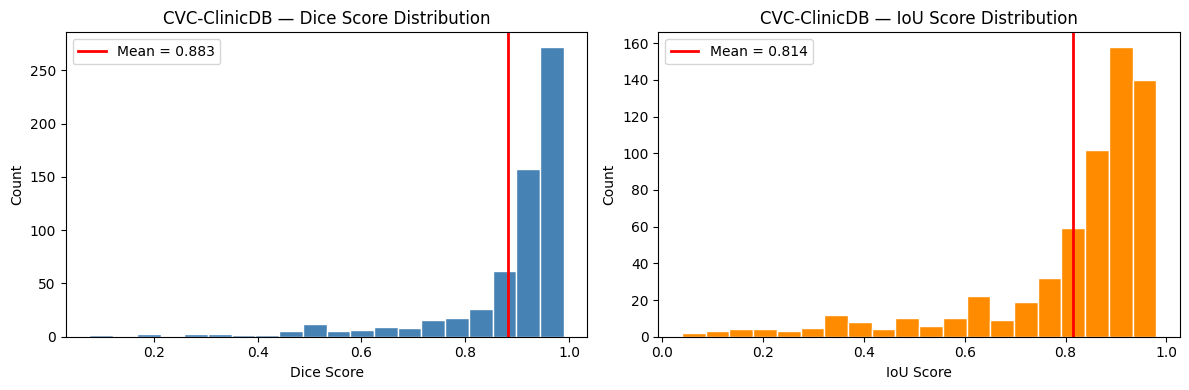

Distribution plot saved.


In [22]:
# ── 14.4  Dice / IoU distribution histogram ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(cvc_dices, bins=20, color='steelblue', edgecolor='white')
axes[0].axvline(np.mean(cvc_dices), color='red', lw=2,
                label=f'Mean = {np.mean(cvc_dices):.3f}')
axes[0].set_title('CVC-ClinicDB — Dice Score Distribution')
axes[0].set_xlabel('Dice Score'); axes[0].set_ylabel('Count')
axes[0].legend()

axes[1].hist(cvc_ious, bins=20, color='darkorange', edgecolor='white')
axes[1].axvline(np.mean(cvc_ious), color='red', lw=2,
                label=f'Mean = {np.mean(cvc_ious):.3f}')
axes[1].set_title('CVC-ClinicDB — IoU Score Distribution')
axes[1].set_xlabel('IoU Score'); axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig('cvc_clinicdb_score_distribution.png', dpi=100)
plt.show()
print('Distribution plot saved.')


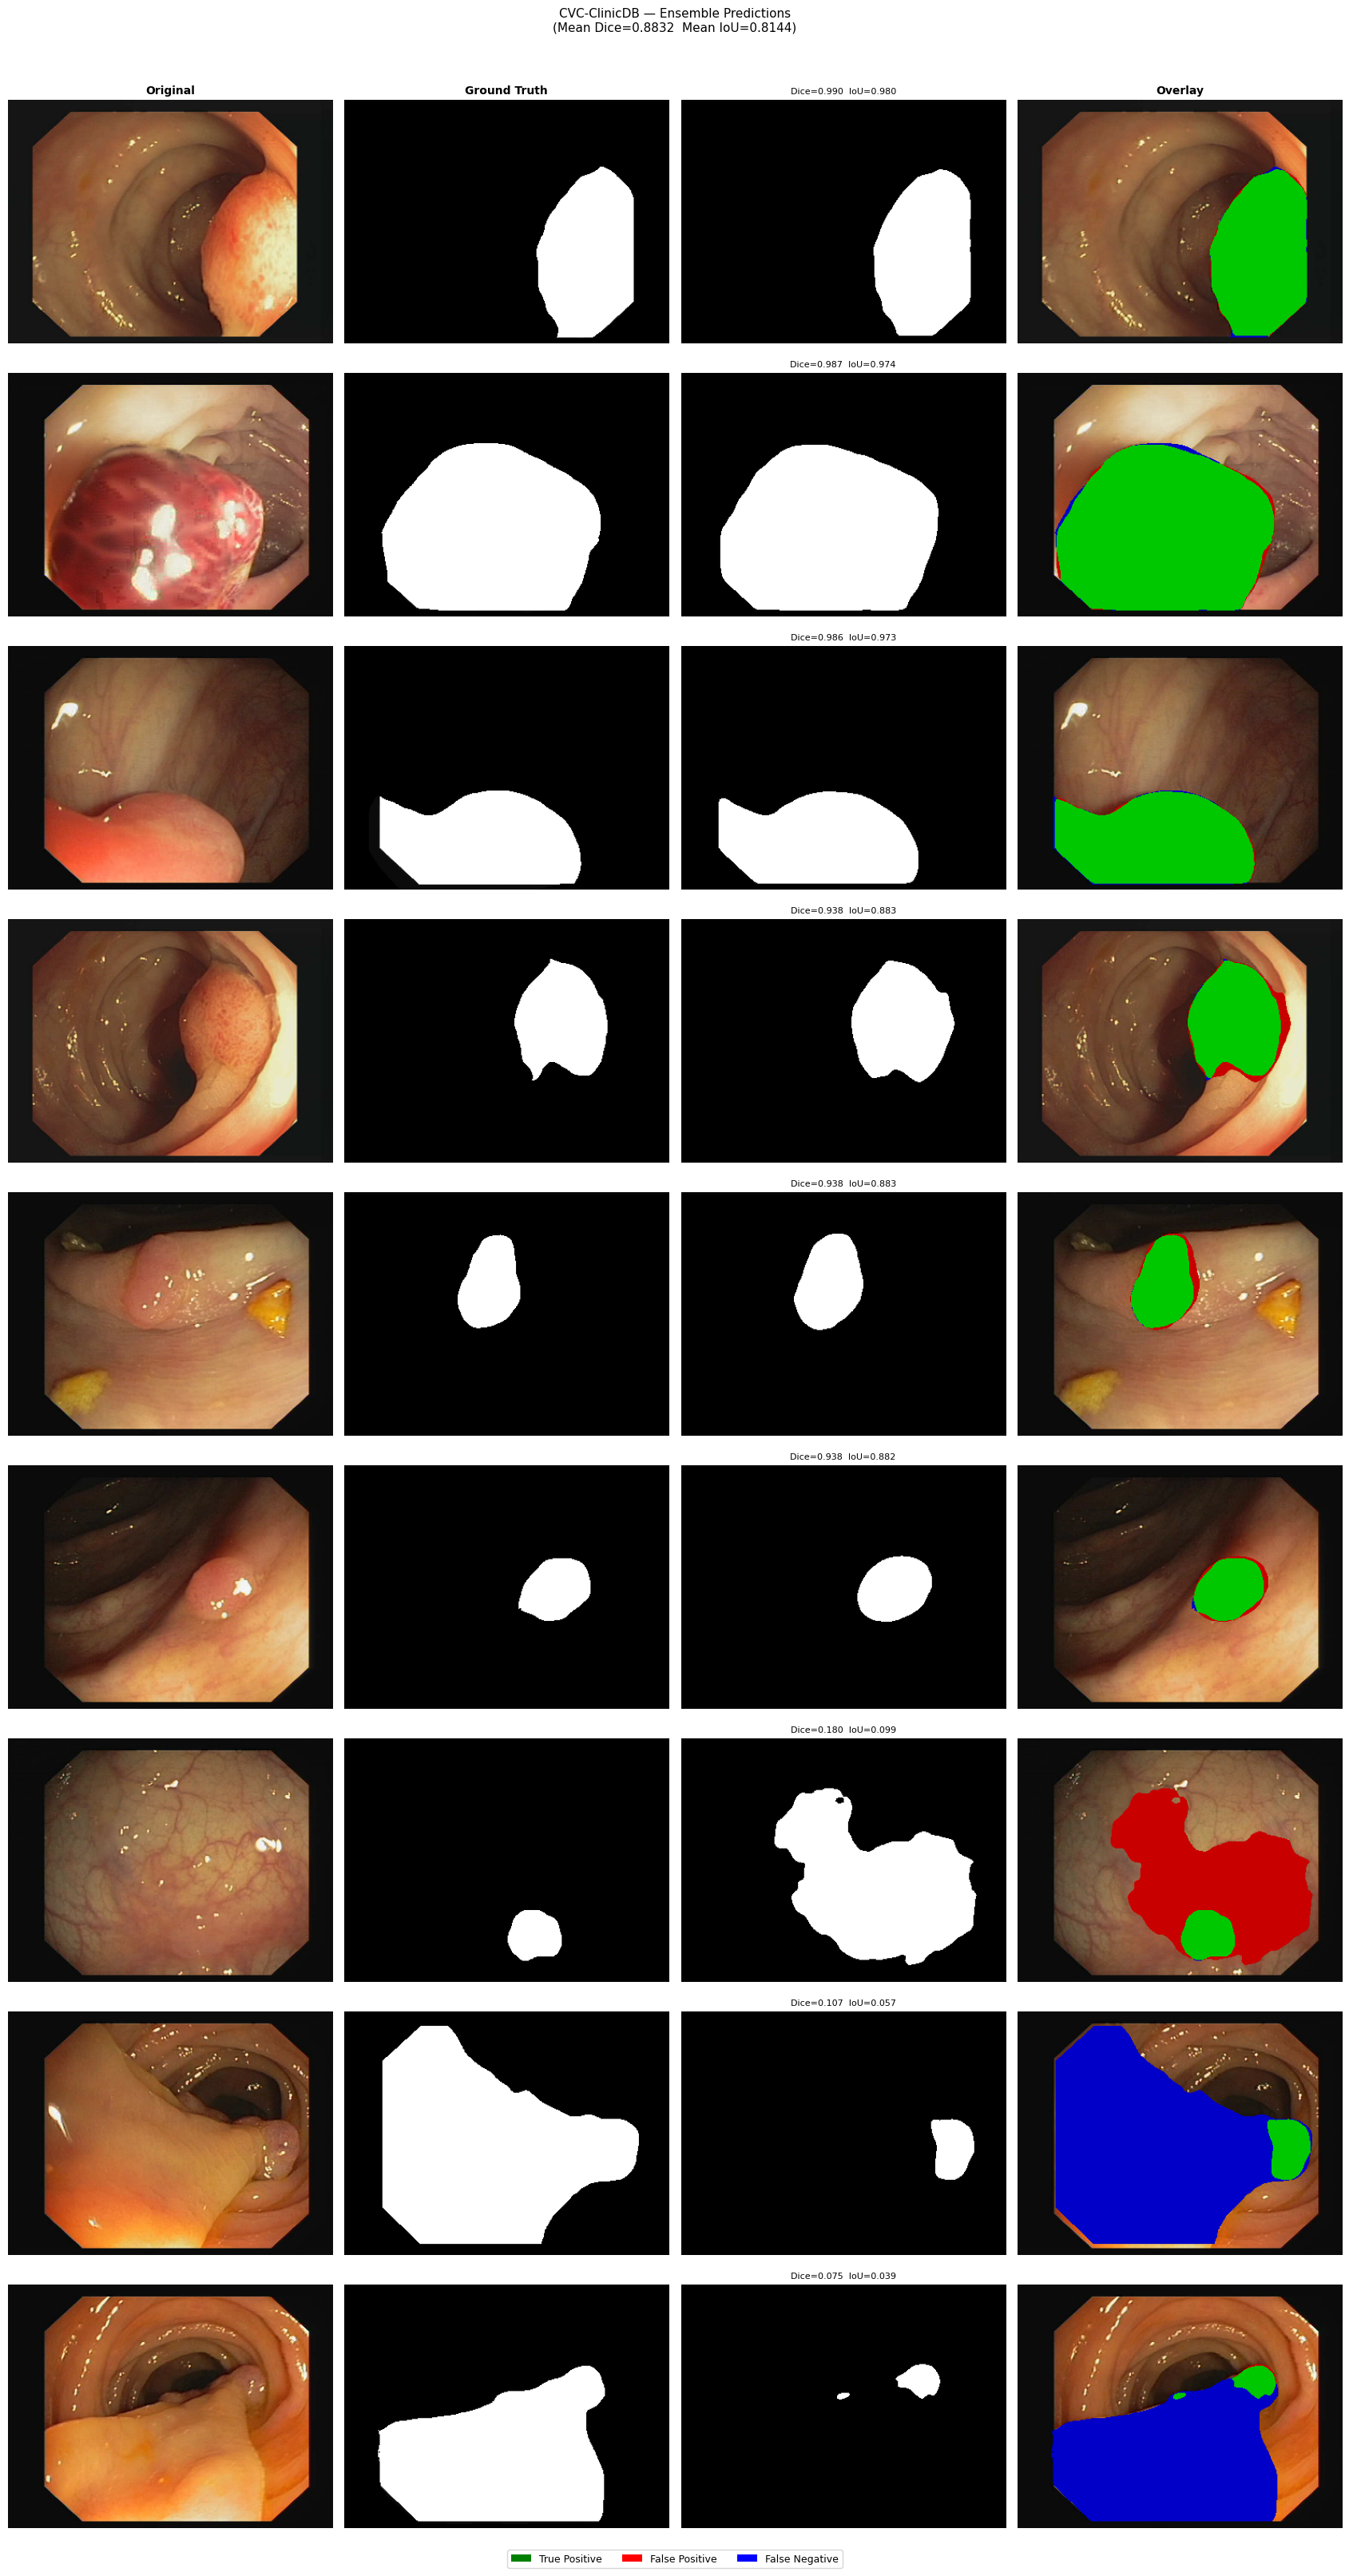

Prediction visualisation saved to: cvc_clinicdb_predictions.png


In [23]:
# ── 14.5  Visual strip — best / median / worst predictions ───────────────────
# Show the top-3 best, the 3 around the median, and the 3 worst predictions
sorted_results = sorted(cvc_results, key=lambda r: r['dice'], reverse=True)
n_total = len(sorted_results)

# Pick indices: 0,1,2  |  mid-2, mid-1, mid  |  -3,-2,-1
mid = n_total // 2
sample_indices = [0, 1, 2,
                  max(0, mid - 1), mid, min(n_total - 1, mid + 1),
                  max(0, n_total - 3), n_total - 2, n_total - 1]
# Remove duplicates while preserving order
seen = set()
unique_indices = [i for i in sample_indices
                  if not (i in seen or seen.add(i))]
samples = [sorted_results[i] for i in unique_indices]

N = len(samples)
fig, axes = plt.subplots(N, 4, figsize=(17, N * 3.5))
if N == 1:
    axes = axes[np.newaxis, :]

col_titles = ['Original', 'Ground Truth', 'Predicted Mask', 'Overlay']
for ax, ct in zip(axes[0], col_titles):
    ax.set_title(ct, fontsize=10, fontweight='bold')

for row, r in enumerate(samples):
    img_bgr = cv2.imread(str(r['orig_path']))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    gt_raw  = cv2.imread(str(r['gt_path']), cv2.IMREAD_GRAYSCALE)
    pred    = r['pred_mask']

    # Resize GT/pred to display size if needed
    H, W = img_rgb.shape[:2]
    gt_disp   = cv2.resize(gt_raw, (W, H), interpolation=cv2.INTER_NEAREST)
    pred_disp = cv2.resize(pred,   (W, H), interpolation=cv2.INTER_NEAREST)

    # Colour overlay: green = TP, red = FP, blue = FN
    gt_b   = (gt_disp > 127)
    pred_b = (pred_disp > 127)
    overlay = img_rgb.copy()
    overlay[gt_b  &  pred_b] = [0,   200, 0  ]   # TP — green
    overlay[pred_b & ~gt_b ] = [200,  0,  0  ]   # FP — red
    overlay[gt_b  & ~pred_b] = [0,    0,  200]   # FN — blue

    axes[row, 0].imshow(img_rgb);              axes[row, 0].axis('off')
    axes[row, 1].imshow(gt_disp,  cmap='gray'); axes[row, 1].axis('off')
    axes[row, 2].imshow(pred_disp, cmap='gray'); axes[row, 2].axis('off')
    axes[row, 3].imshow(overlay);              axes[row, 3].axis('off')

    axes[row, 0].set_ylabel(r['name'][:18], fontsize=7, rotation=0,
                             labelpad=70, va='center')
    axes[row, 2].set_title(
        f"Dice={r['dice']:.3f}  IoU={r['iou']:.3f}", fontsize=8)

# Legend patch
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='green', label='True Positive'),
    Patch(facecolor='red',   label='False Positive'),
    Patch(facecolor='blue',  label='False Negative'),
]
fig.legend(handles=legend_elements, loc='lower center',
           ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.01))

plt.suptitle('CVC-ClinicDB — Ensemble Predictions\n'
             f'(Mean Dice={np.mean(cvc_dices):.4f}  '
             f'Mean IoU={np.mean(cvc_ious):.4f})',
             fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig('cvc_clinicdb_predictions.png', dpi=100, bbox_inches='tight')
plt.show()
print('Prediction visualisation saved to: cvc_clinicdb_predictions.png')


In [24]:
# ── 14.6  Compare CVC-ClinicDB vs Medico (fold-5 held-out) results ───────────
print('\n' + '=' * 60)
print('  CROSS-DATASET COMPARISON')
print('=' * 60)
print(f"  {'Dataset':<30} {'Mean Dice':>10} {'Mean IoU':>10} {'# Samples':>10}")
print(f"  {'-'*60}")

# Medico held-out (computed in Section 12 above)
medico_dice = np.mean(all_dice_v)
medico_iou  = np.mean(all_iou_v)
print(f"  {'Medico (fold-5 held-out)':<30} {medico_dice:>10.4f} {medico_iou:>10.4f} {len(all_dice_v):>10}")

# CVC-ClinicDB
print(f"  {'CVC-ClinicDB (external)':<30} {np.mean(cvc_dices):>10.4f} {np.mean(cvc_ious):>10.4f} {len(cvc_dices):>10}")
print('=' * 60)
print()
print('Reference (literature benchmarks on CVC-ClinicDB):')
print('  PraNet  (2020)  Dice ≈ 0.899  IoU ≈ 0.849')
print('  HardNet (2021)  Dice ≈ 0.912  IoU ≈ 0.857')
print('  SANet   (2021)  Dice ≈ 0.916  IoU ≈ 0.859')
print()
print('Note: literature numbers are from models trained on Kvasir+ClinicDB;')
print('this model was trained on Medico/Kvasir-SEG only, so a gap is expected.')



  CROSS-DATASET COMPARISON
  Dataset                         Mean Dice   Mean IoU  # Samples
  ------------------------------------------------------------
  Medico (fold-5 held-out)           0.9633     0.9309        200
  CVC-ClinicDB (external)            0.8832     0.8144        612

Reference (literature benchmarks on CVC-ClinicDB):
  PraNet  (2020)  Dice ≈ 0.899  IoU ≈ 0.849
  HardNet (2021)  Dice ≈ 0.912  IoU ≈ 0.857
  SANet   (2021)  Dice ≈ 0.916  IoU ≈ 0.859

Note: literature numbers are from models trained on Kvasir+ClinicDB;
this model was trained on Medico/Kvasir-SEG only, so a gap is expected.
